<a href="https://colab.research.google.com/github/HeyWinTomsy/MN/blob/main/%D0%9B%D0%A05_%D0%90%D0%BD%D1%82%D1%80%D0%BF%D0%BE%D0%B2%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [85]:
# Імпортуйте необхідні бібліотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

import warnings
warnings.filterwarnings("ignore")


In [86]:
# Завантажте датасет з Kaggle
!wget -q -O weather.csv "https://www.kaggle.com/api/v1/datasets/download/yug201/daily-climate-time-series-data-delhi-india"
!unzip -o -q weather.csv -d weather_data
import os
csv_files = [f for f in os.listdir("weather_data") if f.lower().endswith(".csv")]
print(csv_files)

['kaggel_weather_2013_to_2024.csv']


In [87]:
# Зчитайте датасет у DataFrame та перегляньте дані

if not csv_files:
    raise FileNotFoundError(
        "У папці weather_data не знайдено CSV-файлів."
    )

for i, file in enumerate(csv_files):
    print(f"{i}: {file}")

file_path = os.path.join("weather_data", csv_files[0])

df = pd.read_csv(file_path)

print("\nЗавантажений файл:", file_path)
print("Розмір датасету:", df.shape)

display(df.head())

0: kaggel_weather_2013_to_2024.csv

Завантажений файл: weather_data/kaggel_weather_2013_to_2024.csv
Розмір датасету: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Підготовка даних

In [88]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу
if "date" in df.columns:
    df = df.rename(columns={"date": "DATE"})

df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")

df = df.dropna(subset=["DATE"])

df = df.sort_values("DATE")

columns_to_drop = [
    col for col in ["Unnamed: 0", "index"]
    if col in df.columns
]

df = df.drop(columns=columns_to_drop)

df = df.set_index("DATE")

print("Перші 5 рядків після обробки:")
display(df.head())

print("\nІнформація про датасет:")
df.info()

print("\nПропущені значення:")
print(df.isnull().sum())

Перші 5 рядків після обробки:


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month        

In [89]:
# Перегляньте інформацію про структуру датасету
print("Інформація про структуру датасету:")
df.info()

print("\nПерші 5 рядків датасету:")
display(df.head())

print("\nРозмір датасету (рядки, стовпці):")
print(df.shape)

print("\nНазви стовпців:")
print(df.columns.tolist())


Інформація про структуру датасету:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  mon

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Розмір датасету (рядки, стовпці):
(3557, 27)

Назви стовпців:
['tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


In [90]:
# Перевірте наявність пропущених значень
print("\nКількість пропущених значень у кожному стовпці:")
print(df.isnull().sum())

print("\nЗагальна кількість пропущених значень:")
print(df.isnull().sum().sum())

print("\nВідсоток пропущених значень у кожному стовпці:")
print((df.isnull().mean() * 100).round(2))


Кількість пропущених значень у кожному стовпці:
tempmax                  0
tempmin                  0
temp                     0
feelslikemax             0
feelslikemin             0
feelslike                0
humidity                 0
precip                   0
precipprob               0
precipcover              0
windspeed                0
sealevelpressure         0
conditions               0
Year                     0
month                    0
dayofweek                0
dayofyear                0
year-2000                0
weekofyear               0
tempmax_humidity         0
tempmin_humidity         0
temp_humidity            0
feelslikemax_humidity    0
feelslikemin_humidity    0
feelslike_humidity       0
temp_range               0
heat_index               0
dtype: int64

Загальна кількість пропущених значень:
0

Відсоток пропущених значень у кожному стовпці:
tempmax                  0.0
tempmin                  0.0
temp                     0.0
feelslikemax             0.0
fee

Графік температури

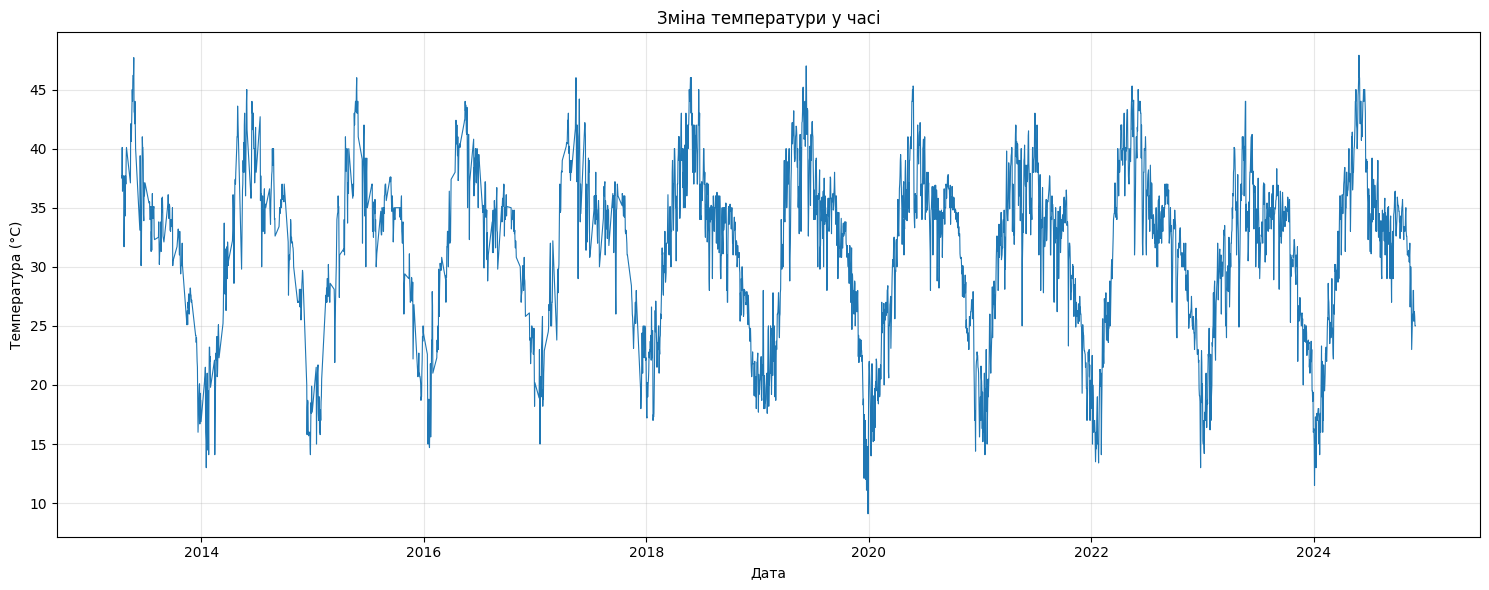

In [91]:
# Побудуйте графік зміни температури у часі
temp_col = next(
    (col for col in df.columns
     if "temp" in col.lower() or "temperature" in col.lower()),
    None
)

if temp_col is not None:
    plt.figure(figsize=(15, 6))

    plt.plot(df.index, df[temp_col], linewidth=0.8)

    plt.title("Зміна температури у часі")
    plt.xlabel("Дата")
    plt.ylabel("Температура (°C)")
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    print("Стовпець температури не знайдено.")
    print("Доступні стовпці:", df.columns.tolist())

Ковзне середнє

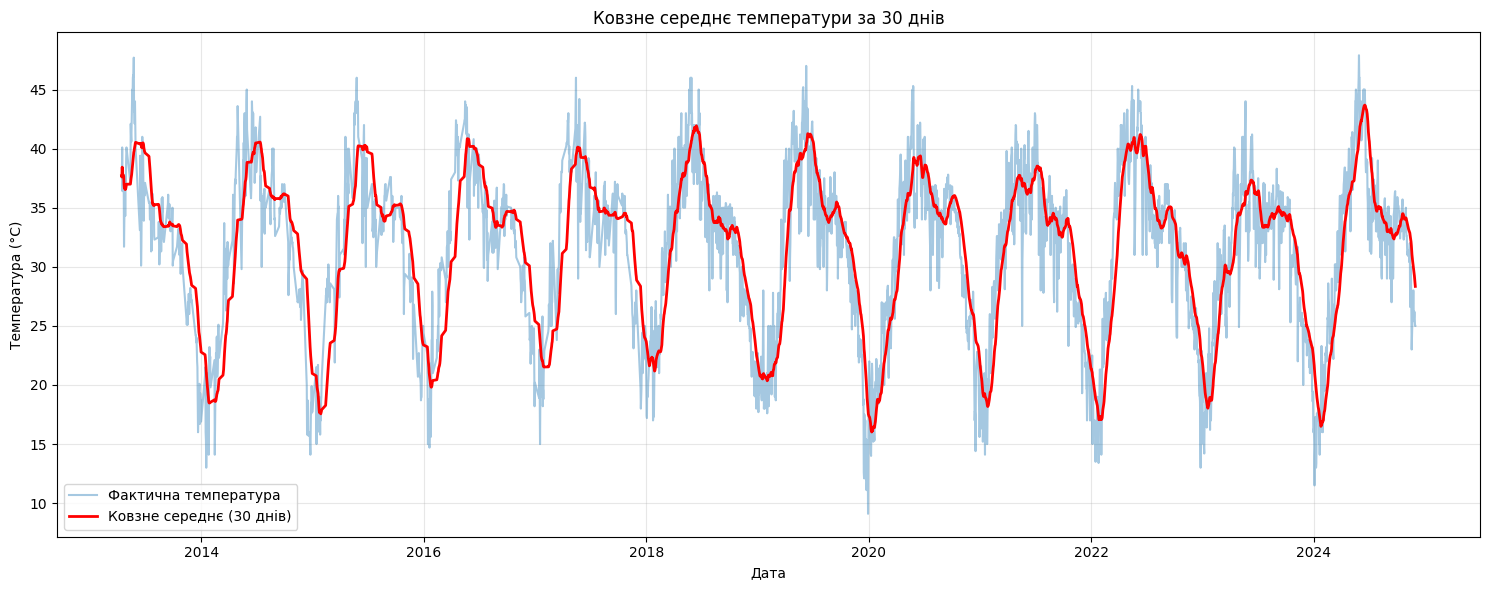

In [92]:
# Обчисліть та візуалізуйте ковзне середнє температури
temp_col = next(
    (col for col in df.columns
     if "temp" in col.lower() or "temperature" in col.lower()),
    None
)

if temp_col is None:
    print("Стовпець температури не знайдено.")
    print("Доступні стовпці:", df.columns.tolist())
else:
    df["rolling_mean"] = df[temp_col].rolling(
        window=30,
        min_periods=1
    ).mean()

    plt.figure(figsize=(15, 6))

    plt.plot(
        df.index,
        df[temp_col],
        label="Фактична температура",
        alpha=0.4
    )

    plt.plot(
        df.index,
        df["rolling_mean"],
        label="Ковзне середнє (30 днів)",
        color="red",
        linewidth=2
    )

    plt.title("Ковзне середнє температури за 30 днів")
    plt.xlabel("Дата")
    plt.ylabel("Температура (°C)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

Розподіл температури

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

df.columns = df.columns.astype(str).str.strip()

temp_col = next(
    (col for col in df.columns
     if "temp" in col.lower() or "temperature" in col.lower()),
    None
)

if temp_col is None:
    print("Стовпець температури не знайдено.")
    print("Доступні стовпці:", df.columns.tolist())
else:
    df[temp_col] = pd.to_numeric(df[temp_col], errors="coerce")

    df = df.sort_index()
    df = df.dropna(subset=[temp_col])

    ts = df[temp_col].astype(float)

    print("Стовпець температури:", temp_col)
    print("Кількість спостережень:", len(ts))
    print("Період:", ts.index.min(), "—", ts.index.max())
    display(ts.head())

Стовпець температури: tempmax
Кількість спостережень: 3557
Період: 2013-04-14 00:00:00 — 2024-11-30 00:00:00


,tempmax
DATE,
2013-04-14,37.7
2013-04-15,37.5
2013-04-16,40.1
2013-04-17,36.4
2013-04-18,37.5


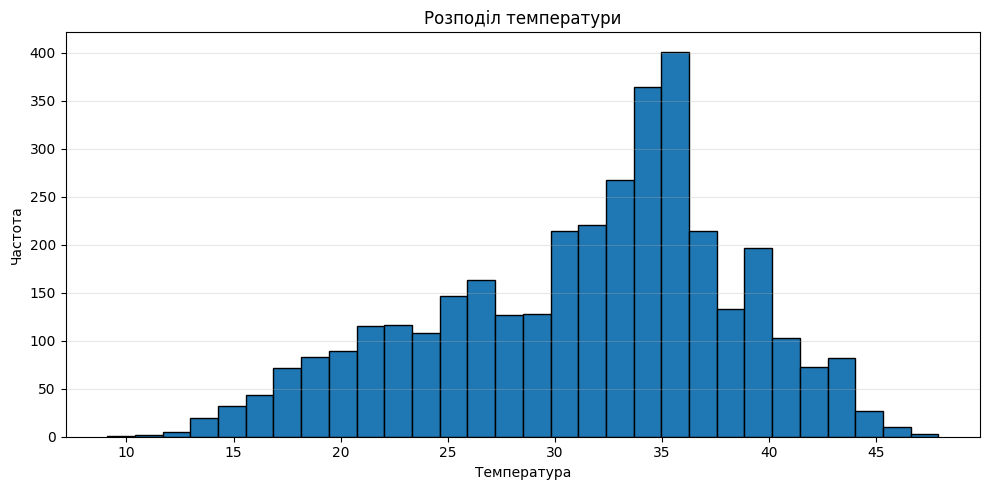

In [94]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10, 5))
plt.hist(ts, bins=30, edgecolor="black")
plt.title("Розподіл температури")
plt.xlabel("Температура")
plt.ylabel("Частота")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

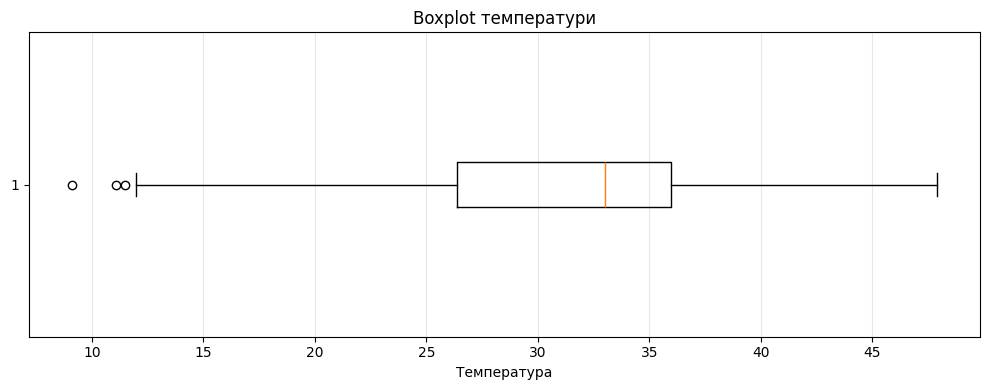

In [95]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(10, 4))
plt.boxplot(ts, vert=False)
plt.title("Boxplot температури")
plt.xlabel("Температура")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Аналіз автокореляції
ACF

PACF

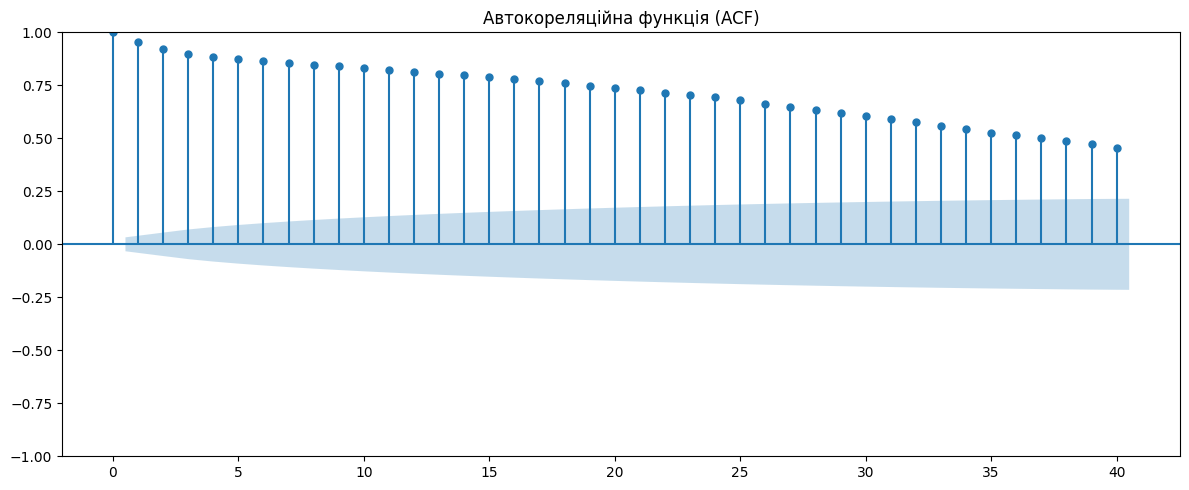

In [96]:
# Побудуйте графік автокореляційної функції (ACF)
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))
plot_acf(ts, lags=min(40, len(ts) // 2 - 1), ax=plt.gca())
plt.title("Автокореляційна функція (ACF)")
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

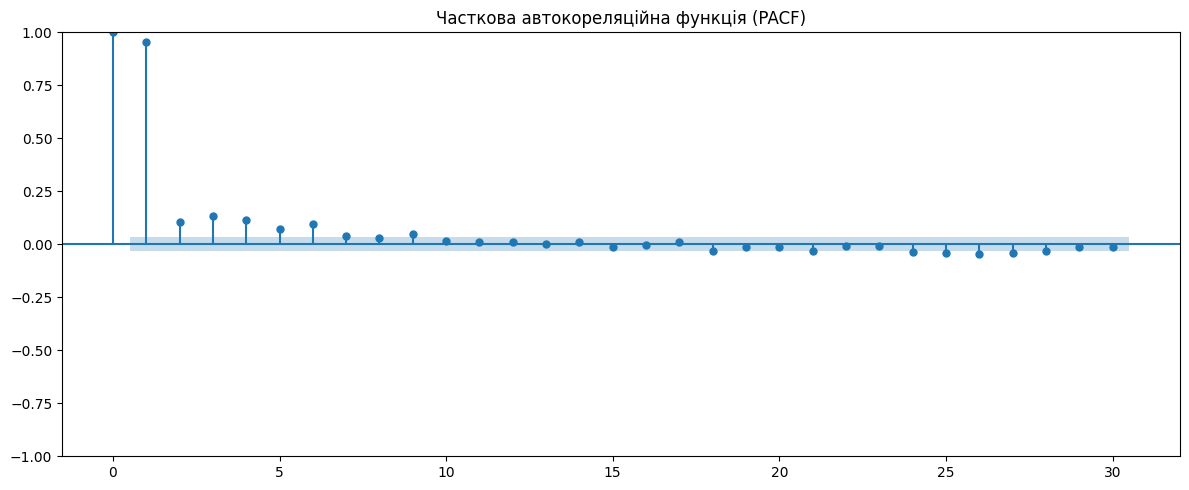

In [97]:
# Побудуйте графік часткової автокореляційної функції (PACF)
from statsmodels.graphics.tsaplots import plot_pacf

plt.figure(figsize=(12, 5))
plot_pacf(
    ts,
    lags=min(30, len(ts) // 2 - 1),
    method="ywm",
    ax=plt.gca()
)
plt.title("Часткова автокореляційна функція (PACF)")
plt.tight_layout()
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

Розмір train: 2845
Розмір test: 712
Остання дата train: 2022-12-19 00:00:00
Перша дата test: 2022-12-20 00:00:00


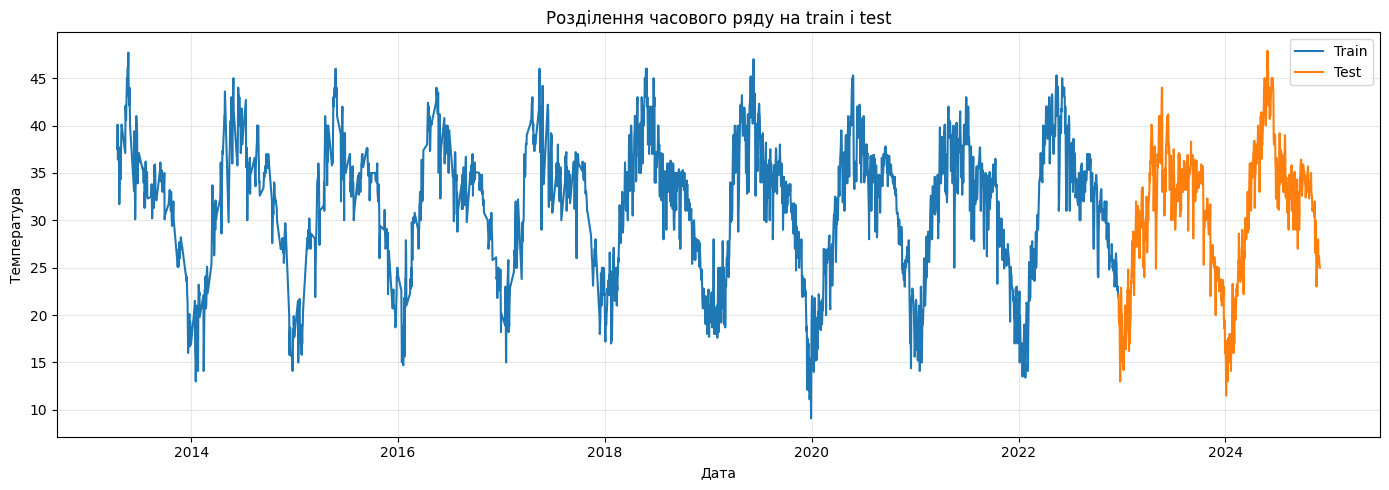

In [98]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
split_idx = int(len(ts) * 0.8)

train = ts.iloc[:split_idx]
test = ts.iloc[split_idx:]

print("Розмір train:", len(train))
print("Розмір test:", len(test))
print("Остання дата train:", train.index[-1])
print("Перша дата test:", test.index[0])

plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.title("Розділення часового ряду на train і test")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [102]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import numpy as np

# 1. Підготовка даних
train = train.dropna().copy()
test = test.dropna().copy()

# Видаляємо дублікати дат, якщо вони залишилися
train = train.groupby(level=0).mean().sort_index()
test = test.groupby(level=0).mean().sort_index()

# 2. Створюємо часовий ряд із числовим індексом
train_arima = pd.Series(
    train.to_numpy(dtype=float),
    index=pd.RangeIndex(start=0, stop=len(train))
)

# 3. Навчання ARIMA
arima_model = ARIMA(
    train_arima,
    order=(5, 1, 0)
)

arima_fitted = arima_model.fit()

# 4. Прогноз на кількість значень тестової вибірки
arima_values = arima_fitted.forecast(steps=len(test))

# 5. Прив'язуємо прогноз до реальних дат тестової вибірки
arima_pred = pd.Series(
    np.asarray(arima_values),
    index=test.index,
    name="ARIMA"
)

print("Модель ARIMA навчена успішно.")
print("Кількість прогнозів:", len(arima_pred))
print("\nПерші прогнозовані значення:")
display(arima_pred.head())

Модель ARIMA навчена успішно.
Кількість прогнозів: 712

Перші прогнозовані значення:


,ARIMA
DATE,
2022-12-20,22.125385
2022-12-21,22.262823
2022-12-22,22.327750
2022-12-23,22.371180
2022-12-24,22.412602


In [103]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fitted.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2844
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -6109.741
Date:                Fri, 23 Oct 2026   AIC                          12231.482
Time:                        18:48:00   BIC                          12267.197
Sample:                             0   HQIC                         12244.364
                               - 2844                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1819      0.015    -11.893      0.000      -0.212      -0.152
ar.L2         -0.2015      0.018    -11.131      0.000      -0.237      -0.166
ar.L3         -0.1589      0.019     -8.184      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

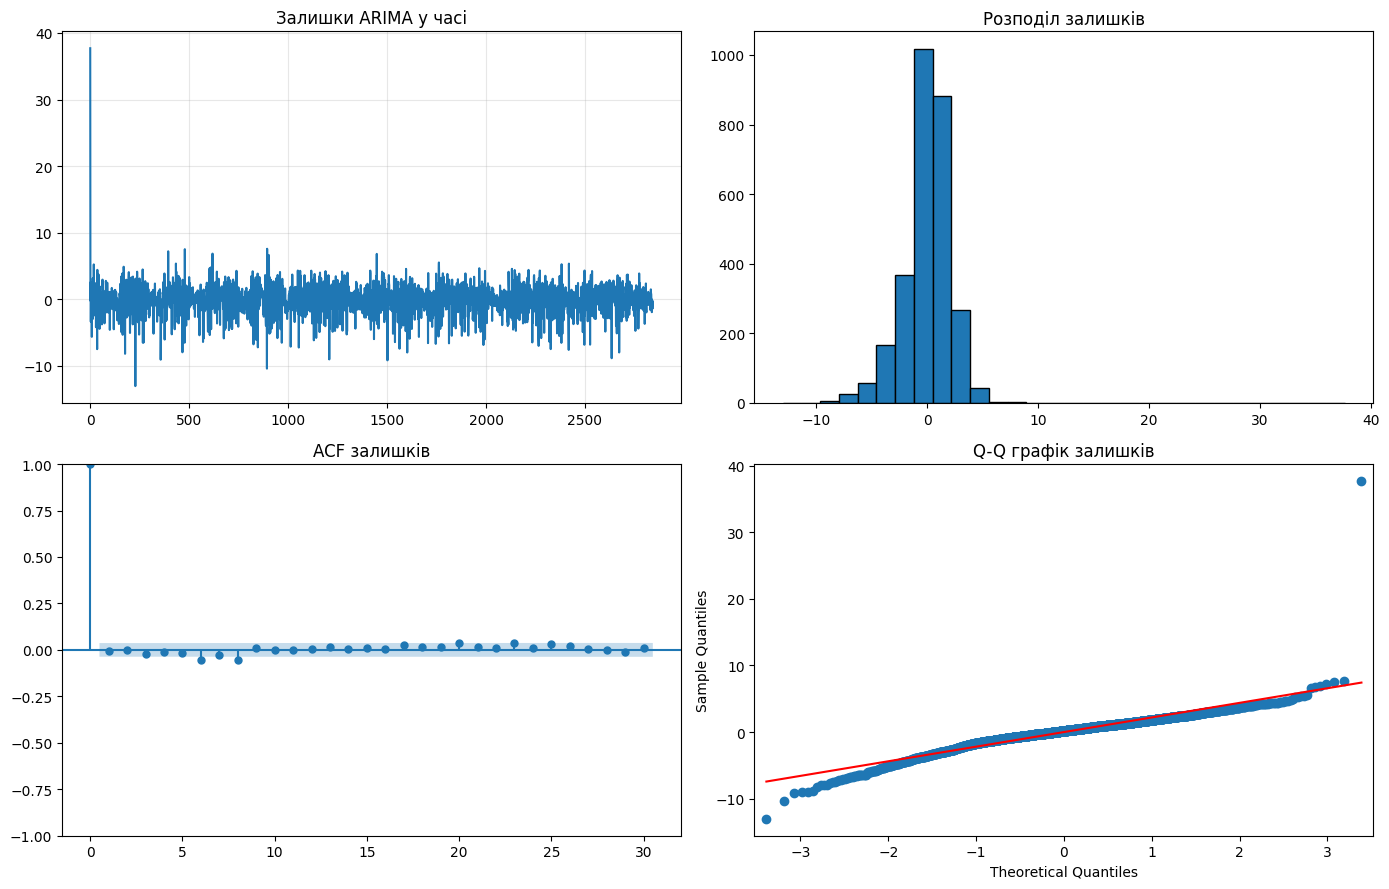

In [104]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = arima_fitted.resid

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(residuals)
axes[0, 0].set_title("Залишки ARIMA у часі")
axes[0, 0].grid(alpha=0.3)

axes[0, 1].hist(residuals, bins=30, edgecolor="black")
axes[0, 1].set_title("Розподіл залишків")

plot_acf(
    residuals,
    lags=min(30, len(residuals) // 2 - 1),
    ax=axes[1, 0]
)
axes[1, 0].set_title("ACF залишків")

from statsmodels.graphics.gofplots import qqplot
qqplot(residuals, line="s", ax=axes[1, 1])
axes[1, 1].set_title("Q-Q графік залишків")

plt.tight_layout()
plt.show()

In [105]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    mask = np.abs(actual) > 1e-8

    if mask.any():
        mape = np.mean(
            np.abs((actual[mask] - predicted[mask]) / actual[mask])
        ) * 100
    else:
        mape = np.nan

    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape}


arima_metrics = calculate_metrics(test, arima_pred)

print("Метрики ARIMA:")
for metric, value in arima_metrics.items():
    print(f"{metric}: {value:.4f}")

Метрики ARIMA:
MAE: 9.7497
RMSE: 11.1252
MAPE (%): 29.6894


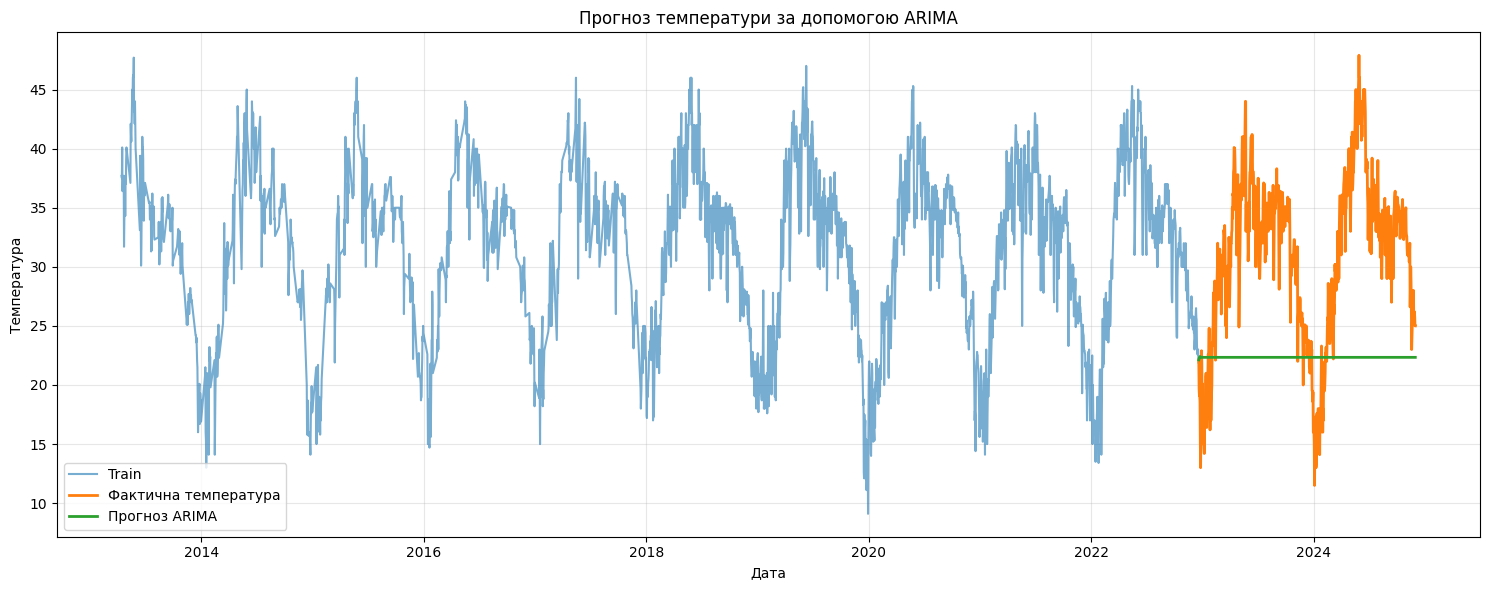

In [106]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(15, 6))
plt.plot(train.index, train, label="Train", alpha=0.6)
plt.plot(test.index, test, label="Фактична температура", linewidth=2)
plt.plot(arima_pred.index, arima_pred, label="Прогноз ARIMA", linewidth=2)

plt.title("Прогноз температури за допомогою ARIMA")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [109]:
# Підготуйте дані у форматі, необхідному для Prophet
%pip -q install prophet
from prophet import Prophet

prophet_df = pd.DataFrame({
    "ds": pd.to_datetime(ts.index),
    "y": ts.values
})

# Використовуємо ті самі межі train/test, що й для ARIMA
prophet_train = prophet_df.iloc[:split_idx].copy()
prophet_test = prophet_df.iloc[split_idx:].copy()

print("Дані для Prophet:")
display(prophet_train.head())

print("Кількість тренувальних записів:", len(prophet_train))
print("Кількість тестових записів:", len(prophet_test))

Дані для Prophet:


,ds,y
0,2013-04-14,37.7
1,2013-04-15,37.5
2,2013-04-16,40.1
3,2013-04-17,36.4
4,2013-04-18,37.5


Кількість тренувальних записів: 2845
Кількість тестових записів: 712


In [110]:
# Створіть та навчіть модель Prophet
prophet_model = Prophet(
    yearly_seasonality="auto",
    weekly_seasonality="auto",
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

print("Модель Prophet навчена.")

Модель Prophet навчена.


Прогноз

In [111]:
# Побудуйте прогноз Prophet для тестового періоду
# Формуємо дати саме тестового періоду
future_test = prophet_test[["ds"]].copy()

prophet_forecast = prophet_model.predict(future_test)

prophet_pred = pd.Series(
    prophet_forecast["yhat"].to_numpy(),
    index=test.index,
    name="Prophet"
)

display(prophet_forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())

,ds,yhat,yhat_lower,yhat_upper
0,2022-12-20,20.362883,16.870910,23.641874
1,2022-12-21,20.154605,16.335634,23.495837
2,2022-12-22,19.937714,16.394491,23.243483
3,2022-12-23,19.750789,16.402813,23.180052
4,2022-12-24,19.541161,16.003622,22.926359


In [112]:
# Обчисліть MAE, RMSE, MAPE для Prophet
prophet_metrics = calculate_metrics(test, prophet_pred)

print("Метрики Prophet:")
for metric, value in prophet_metrics.items():
    print(f"{metric}: {value:.4f}")

Метрики Prophet:
MAE: 2.3378
RMSE: 3.0343
MAPE (%): 8.2814


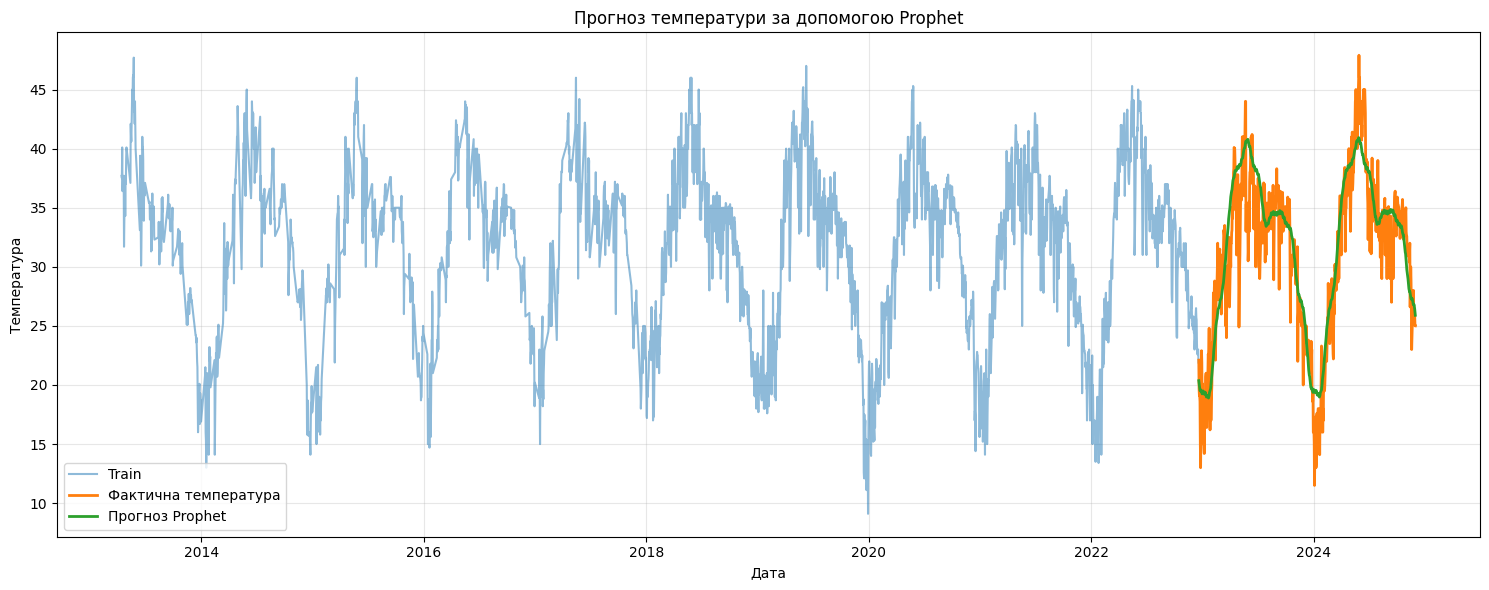

In [113]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(15, 6))
plt.plot(train.index, train, label="Train", alpha=0.5)
plt.plot(test.index, test, label="Фактична температура", linewidth=2)
plt.plot(prophet_pred.index, prophet_pred, label="Прогноз Prophet", linewidth=2)

plt.title("Прогноз температури за допомогою Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

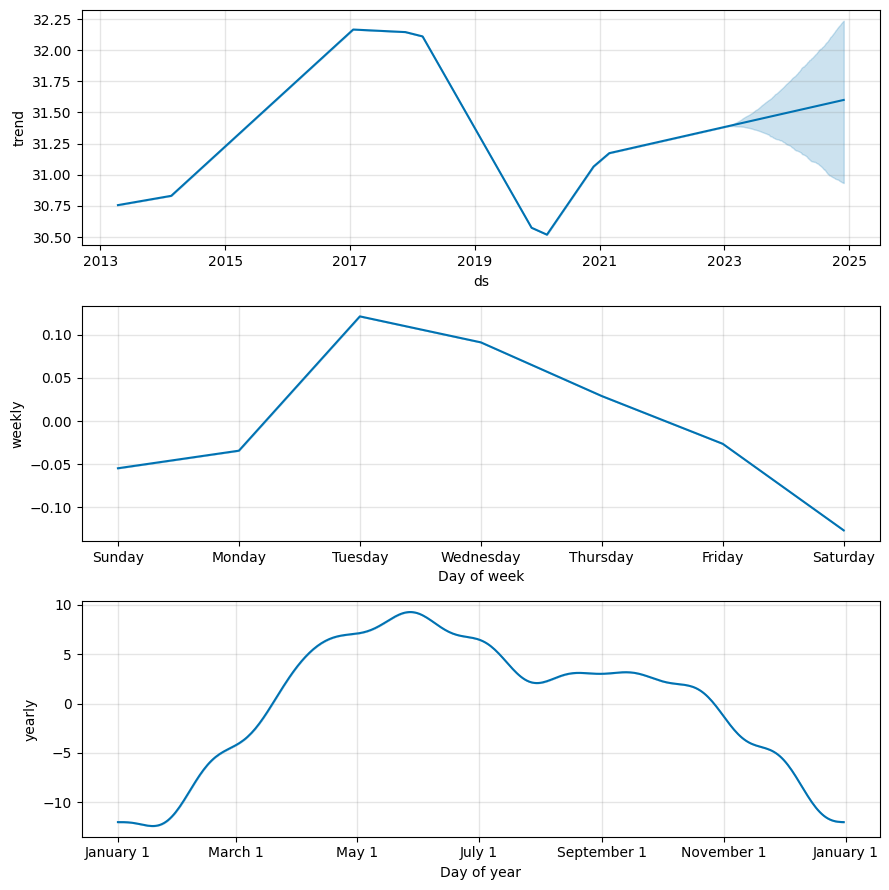

In [114]:
# Побудуйте компоненти моделі Prophet
prophet_model.plot_components(prophet_model.predict(prophet_df[["ds"]]))
plt.tight_layout()
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [115]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
from sklearn.preprocessing import MinMaxScaler

lookback = 30

# Масштабування на основі тільки train
scaler = MinMaxScaler()
scaler.fit(ts.iloc[:split_idx].to_numpy().reshape(-1, 1))

scaled_values = scaler.transform(
    ts.to_numpy().reshape(-1, 1)
).flatten()

X_all = []
y_all = []
target_positions = []

for i in range(lookback, len(scaled_values)):
    X_all.append(scaled_values[i - lookback:i])
    y_all.append(scaled_values[i])
    target_positions.append(i)

X_all = np.array(X_all)
y_all = np.array(y_all)
target_positions = np.array(target_positions)

# Ділимо за позицією цільового значення, без перемішування
train_mask = target_positions < split_idx
test_mask = target_positions >= split_idx

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_test = X_all[test_mask]
y_test = y_all[test_mask]

test_positions = target_positions[test_mask]

# LSTM очікує форму (кількість зразків, кроки часу, ознаки)
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2815, 30, 1)
y_train: (2815,)
X_test: (712, 30, 1)
y_test: (712,)


In [122]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування

train_size = int(len(df) * 0.8)

train = df.iloc[:train_size].copy()
test = df.iloc[train_size:].copy()

print("Розмір тренувальної вибірки:", len(train))
print("Розмір тестової вибірки:", len(test))

Розмір тренувальної вибірки: 2845
Розмір тестової вибірки: 712


In [123]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

tf.keras.utils.set_random_seed(42)

lstm_model = Sequential([
    Input(shape=(lookback, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

print("Архітектуру LSTM створено.")

Архітектуру LSTM створено.


In [124]:
# Навчіть LSTM-модель
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0431 - mae: 0.1502 - val_loss: 0.0087 - val_mae: 0.0768
Epoch 2/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0124 - mae: 0.0882 - val_loss: 0.0113 - val_mae: 0.0893
Epoch 3/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0112 - mae: 0.0845 - val_loss: 0.0073 - val_mae: 0.0691
Epoch 4/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0096 - mae: 0.0778 - val_loss: 0.0100 - val_mae: 0.0835
Epoch 5/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0089 - mae: 0.0742 - val_loss: 0.0069 - val_mae: 0.0664
Epoch 6/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0085 - mae: 0.0720 - val_loss: 0.0071 - val_mae: 0.0676
Epoch 7/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0080 - mae: 0.0699 - val_loss: 0.0074 - val_mae: 0.0691
Epoch 8/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0073 - mae: 0.0664 - val_loss: 0.0076 - val_mae: 0.0706
Epoch 9/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0073 -

In [125]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,573 (349.90 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 59,716 (233.27 KB)

In [126]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)

# Повертаємо значення до початкової шкали температури
lstm_pred_values = scaler.inverse_transform(
    lstm_pred_scaled
).flatten()

lstm_actual_values = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

lstm_pred = pd.Series(
    lstm_pred_values,
    index=ts.index[test_positions],
    name="LSTM"
)

lstm_actual = pd.Series(
    lstm_actual_values,
    index=ts.index[test_positions],
    name="Actual"
)

display(pd.DataFrame({
    "Фактична температура": lstm_actual,
    "Прогноз LSTM": lstm_pred
}).head())

,Фактична температура,Прогноз LSTM
DATE,,
2022-12-20,22.1,22.941916
2022-12-21,19.7,22.635361
2022-12-22,19.1,22.110836
2022-12-23,19.1,21.484074
2022-12-24,18.6,20.882671


In [127]:
# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_test_dates = ts.index[test_positions]

print("Перша дата прогнозу:", lstm_test_dates[0])
print("Остання дата прогнозу:", lstm_test_dates[-1])
print("Кількість прогнозів:", len(lstm_test_dates))

Перша дата прогнозу: 2022-12-20 00:00:00
Остання дата прогнозу: 2024-11-30 00:00:00
Кількість прогнозів: 712


In [128]:
# Обчисліть MAE, RMSE, MAPE для LSTM
lstm_metrics = calculate_metrics(lstm_actual_values, lstm_pred_values)

print("Метрики LSTM:")
for metric, value in lstm_metrics.items():
    print(f"{metric}: {value:.4f}")

Метрики LSTM:
MAE: 2.0475
RMSE: 2.5627
MAPE (%): 6.9999


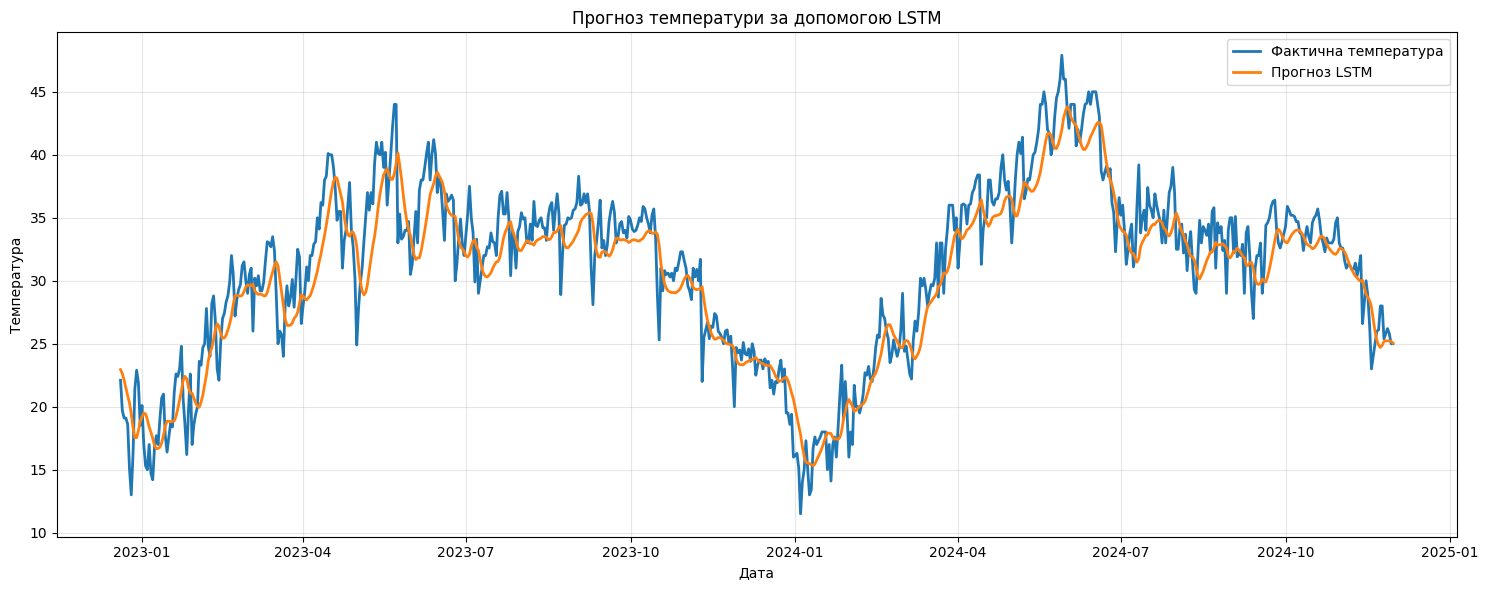

In [129]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(15, 6))
plt.plot(lstm_actual.index, lstm_actual, label="Фактична температура", linewidth=2)
plt.plot(lstm_pred.index, lstm_pred, label="Прогноз LSTM", linewidth=2)

plt.title("Прогноз температури за допомогою LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Порівняння моделей

In [132]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results = pd.DataFrame({
    "Модель": ["ARIMA", "Prophet", "LSTM"],
    "MAE": [
        arima_metrics["MAE"],
        prophet_metrics["MAE"],
        lstm_metrics["MAE"]
    ],
    "RMSE": [
        arima_metrics["RMSE"],
        prophet_metrics["RMSE"],
        lstm_metrics["RMSE"]
    ],
    "MAPE (%)": [
        arima_metrics["MAPE (%)"],
        prophet_metrics["MAPE (%)"],
        lstm_metrics["MAPE (%)"]
    ]
})

results = results.sort_values("RMSE").reset_index(drop=True)

display(results.round(4))

best_mae = results.loc[results["MAE"].idxmin(), "Модель"]
best_rmse = results.loc[results["RMSE"].idxmin(), "Модель"]

valid_mape = results.dropna(subset=["MAPE (%)"])
best_mape = (
    valid_mape.loc[valid_mape["MAPE (%)"].idxmin(), "Модель"]
    if not valid_mape.empty
    else "Неможливо визначити"
)

print("Модель із найменшим MAE:", best_mae)
print("Модель із найменшим RMSE:", best_rmse)
print("Модель із найменшим MAPE:", best_mape)

print("\nПорівняння:")
print(results.round(4).to_string(index=False))

,Модель,MAE,RMSE,MAPE (%)
0,LSTM,2.0475,2.5627,6.9999
1,Prophet,2.3378,3.0343,8.2814
2,ARIMA,9.7497,11.1252,29.6894


Модель із найменшим MAE: LSTM
Модель із найменшим RMSE: LSTM
Модель із найменшим MAPE: LSTM

Порівняння:
 Модель    MAE    RMSE  MAPE (%)
   LSTM 2.0475  2.5627    6.9999
Prophet 2.3378  3.0343    8.2814
  ARIMA 9.7497 11.1252   29.6894


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У ході роботи було проведено аналіз часового ряду та виконано прогнозування майбутніх значень за допомогою моделей ARIMA, Prophet і LSTM. Для оцінювання якості прогнозів використовувалися метрики MAE, RMSE і MAPE, які характеризують величину похибок між фактичними та прогнозованими значеннями. Порівняння результатів дало змогу визначити ефективність кожної моделі. Найкращою вважається модель, яка продемонструвала найменші значення цих метрик. ARIMA підходить для аналізу закономірностей часового ряду, Prophet зручна для виявлення трендів і сезонності, а LSTM здатна враховувати складні нелінійні залежності. Отже, модель із найнижчими показниками MAE, RMSE та MAPE забезпечує найточніше прогнозування на досліджуваних даних.